In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Cannot find complaints_clean.csv")
    PROJECT_ROOT = PROJECT_ROOT.parent

file_path = PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9461, 15)


,complaint_id,make,model,model_year,product_model,filed_date,incident_date,components,crash,fire,number_of_injuries,number_of_deaths,summary,reporting_delay,invalid_incident_date
0,11770133,TOYOTA,CAMRY,2018,CAMRY,2026-10-09,2026-09-29,POWER TRAIN,False,False,0,0,"Total transmission failure at about 107,770 mi...",10.0,False
1,11769969,TOYOTA,CAMRY,2018,CAMRY,2026-10-08,2026-10-06,ENGINE,False,False,0,0,My 2018 Toyota Camry LE went into Limp mode wh...,2.0,False
2,11769124,TOYOTA,CAMRY,2018,CAMRY,2026-10-05,2026-10-03,POWER TRAIN,False,False,0,0,The contact owns a 2018 Toyota Camry. The cont...,2.0,False
3,11768868,TOYOTA,CAMRY,2018,CAMRY,2026-10-04,2026-10-02,FUEL/PROPULSION SYSTEM,False,False,0,0,I am filing a formal complaint regarding a sev...,2.0,False
4,11768335,TOYOTA,CAMRY,2018,CAMRY,2026-10-01,2026-09-29,POWER TRAIN,False,False,0,0,"2018 Toyota Camry approx 126,000 miles. Trans...",2.0,False


In [13]:
print("Missing reporting delays:", df["reporting_delay"].isna().sum())

print("\nReporting delay statistics:")
print(
    df["reporting_delay"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Missing reporting delays: 27

Reporting delay statistics:
count    9434.000000
mean       89.878100
std       229.309075
min         0.000000
25%         2.000000
50%        12.000000
75%        60.750000
90%       239.000000
95%       448.700000
99%      1249.670000
max      2922.000000
Name: reporting_delay, dtype: float64


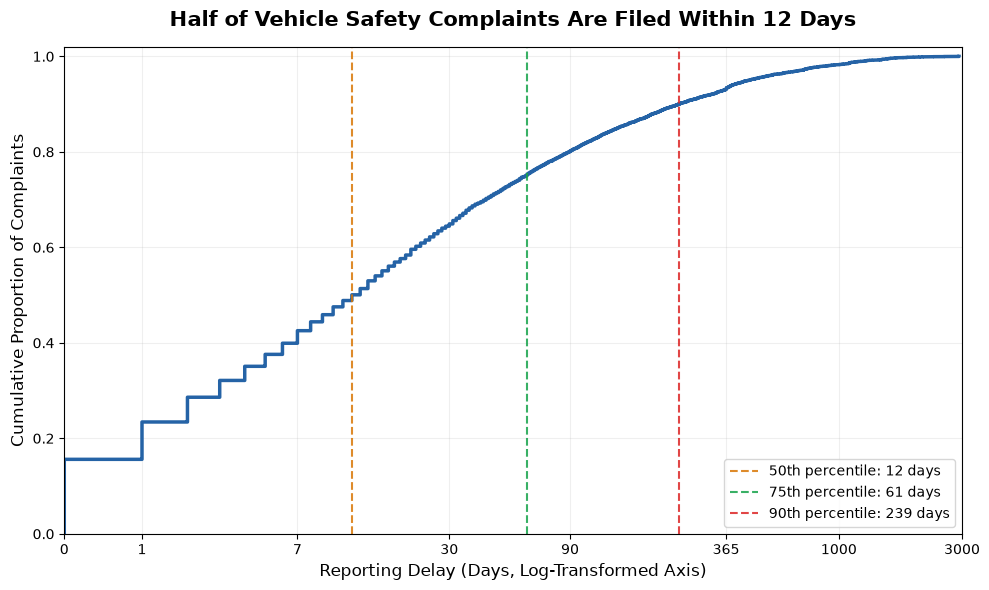

In [14]:
delay = df["reporting_delay"].dropna()

median_delay = delay.median()
p75 = delay.quantile(0.75)
p90 = delay.quantile(0.90)

fig, ax = plt.subplots(figsize=(10, 6))

sns.ecdfplot(
    x=np.log1p(delay),
    ax=ax,
    color="#2563A6",
    linewidth=2.5
)

for value, percentile, color in [
    (median_delay, 50, "#D97706"),
    (p75, 75, "#16A34A"),
    (p90, 90, "#DC2626")
]:
    ax.axvline(
        np.log1p(value),
        color=color,
        linestyle="--",
        alpha=0.85,
        label=f"{percentile}th percentile: {value:.0f} days"
    )

# Show original day values on the transformed axis
ticks = [0, 1, 7, 30, 90, 365, 1000, 3000]
ax.set_xticks(np.log1p(ticks))
ax.set_xticklabels([str(x) for x in ticks])
ax.set_xlim(np.log1p(0), np.log1p(3000))

ax.set_title(
    "Half of Vehicle Safety Complaints Are Filed Within 12 Days",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Reporting Delay (Days, Log-Transformed Axis)", fontsize=12)
ax.set_ylabel("Cumulative Proportion of Complaints", fontsize=12)

ax.set_ylim(0, 1.02)
ax.grid(alpha=0.2)
ax.legend(loc="lower right")

plt.tight_layout()

output_path = PROJECT_ROOT / "figures" / "reporting_delay_ecdf.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

In [15]:
# Create a separate dataframe for this analysis
df_severity = df.copy()

# Convert event indicators to Boolean values
crash = df_severity["crash"].fillna(False).astype(bool)
fire = df_severity["fire"].fillna(False).astype(bool)

# Define severe complaints
df_severity["severe"] = (
    crash
    | fire
    | (df_severity["number_of_injuries"] > 0)
    | (df_severity["number_of_deaths"] > 0)
)

# Keep complaints with valid reporting delays
df_severity = df_severity.dropna(subset=["reporting_delay"])

# Check sample sizes
print("Complaint counts:")
print(df_severity["severe"].value_counts())

# Compare reporting delays
print("\nReporting delay by severity:")
display(
    df_severity.groupby("severe")["reporting_delay"]
    .describe(percentiles=[0.5, 0.75, 0.9])
    .round(1)
)

Complaint counts:
severe
False    8945
True      489
Name: count, dtype: int64

Reporting delay by severity:


,count,mean,std,min,50%,75%,90%,max
severe,,,,,,,,
False,8945.0,89.7,230.3,0.0,12.0,60.0,238.0,2922.0
True,489.0,92.4,211.5,0.0,13.0,67.0,296.4,1673.0


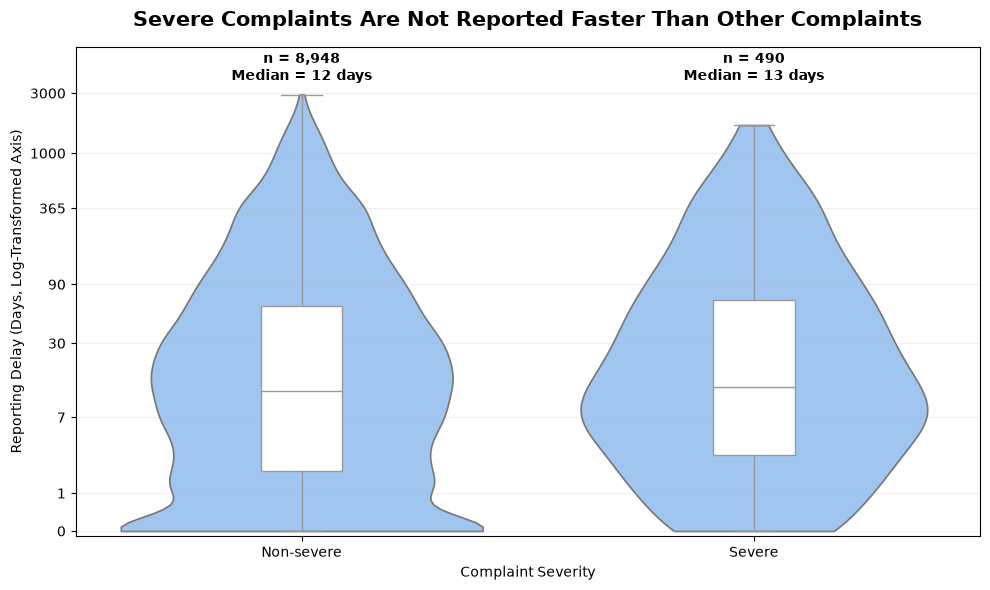

In [16]:
# Prepare plotting data
plot_df = df_severity.copy()

plot_df["Severity"] = plot_df["severe"].map({
    False: "Non-severe",
    True: "Severe"
})

plot_df["Log Delay"] = np.log1p(plot_df["reporting_delay"])

# Create plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(
    data=plot_df,
    x="Severity",
    y="Log Delay",
    order=["Non-severe", "Severe"],
    inner=None,
    cut=0,
    color="#93C5FD",
    ax=ax
)

sns.boxplot(
    data=plot_df,
    x="Severity",
    y="Log Delay",
    order=["Non-severe", "Severe"],
    width=0.18,
    showfliers=False,
    color="white",
    ax=ax
)

# Show reporting delay in original days
ticks = [0, 1, 7, 30, 90, 365, 1000, 3000]
ax.set_yticks(np.log1p(ticks))
ax.set_yticklabels([str(x) for x in ticks])

ax.set_title(
    "Severe Complaints Are Not Reported Faster Than Other Complaints",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Complaint Severity")
ax.set_ylabel("Reporting Delay (Days, Log-Transformed Axis)")

ax.grid(axis="y", alpha=0.2)

# Add sample sizes and median annotations
group_info = [
    ("Non-severe", 8948, 12),
    ("Severe", 490, 13)
]

for i, (name, n, median) in enumerate(group_info):
    ax.text(
        i,
        np.log1p(3500),
        f"n = {n:,}\nMedian = {median} days",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(-0.1, np.log1p(7000))

plt.tight_layout()

output_path = PROJECT_ROOT / "figures" / "severity_reporting_delay.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

In [17]:
from pathlib import Path

figures_dir = PROJECT_ROOT / "figures"

for file in sorted(figures_dir.glob("*.png")):
    print(file.name)

reporting_delay_ecdf.png
severity_reporting_delay.png


In [18]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (9461, 15)
Columns: ['complaint_id', 'make', 'model', 'model_year', 'product_model', 'filed_date', 'incident_date', 'components', 'crash', 'fire', 'number_of_injuries', 'number_of_deaths', 'summary', 'reporting_delay', 'invalid_incident_date']


In [19]:
from pathlib import Path

for name in [
    "reporting_delay_ecdf.png",
    "severity_reporting_delay.png"
]:
    file = PROJECT_ROOT / "figures" / name
    print(name, "exists:", file.exists())

reporting_delay_ecdf.png exists: True
severity_reporting_delay.png exists: True


In [20]:
delay = pd.to_numeric(df["reporting_delay"], errors="coerce")
valid = delay.dropna()
valid = valid[valid >= 0]

print("Valid reporting delays:", len(valid))
print("Median:", valid.median())
print("75th percentile:", valid.quantile(0.75))
print("90th percentile:", valid.quantile(0.90))

Valid reporting delays: 9434
Median: 12.0
75th percentile: 60.75
90th percentile: 239.0


In [21]:
# Convert reporting delay to numeric
df["reporting_delay"] = pd.to_numeric(
    df["reporting_delay"], errors="coerce"
)

# Convert injury and death counts to numeric
injuries = pd.to_numeric(
    df["number_of_injuries"], errors="coerce"
).fillna(0)

deaths = pd.to_numeric(
    df["number_of_deaths"], errors="coerce"
).fillna(0)

# Define severe complaints
df["severe"] = (
    df["crash"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
    | df["fire"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
    | (injuries > 0)
    | (deaths > 0)
)

# Keep valid reporting delays
valid_df = df[
    df["reporting_delay"].notna()
    & (df["reporting_delay"] >= 0)
]

# Compare severe and non-severe complaints
summary = valid_df.groupby("severe")["reporting_delay"].agg(
    ["count", "median", "mean"]
)

print(summary)

        count  median       mean
severe                          
False    8945    12.0  89.742538
True      489    13.0  92.357873


In [22]:
print(df[["crash", "fire"]].dtypes)

print("\nCrash values:")
print(df["crash"].value_counts(dropna=False))

print("\nFire values:")
print(df["fire"].value_counts(dropna=False))

crash    bool
fire     bool
dtype: object

Crash values:
crash
False    9092
True      369
Name: count, dtype: int64

Fire values:
fire
False    9392
True       69
Name: count, dtype: int64
